# Audit Data EV Battery Health

**Proyek akhir Jaringan Saraf Tiruan · MLP dengan backpropagation**

Notebook ini menjawab: data apa yang tersedia, target apa yang layak diprediksi, fitur apa yang dilarang, dan bagaimana data dibagi secara sah?

**Cakupan:** audit kualitas global dan EDA awal **train**. Belum ada imputasi/scaling yang di-fit, training, atau skor model. Keputusan utama: estimasi SOH saat ini untuk baterai baru, bukan prediksi masa depan.

Jalankan semua sel secara berurutan. CSV harus tersedia di `data/raw/ev_battery_health.csv`; instruksi ada di README repositori.

## 1. Lingkungan dan lokasi proyek

Path dicari dari root atau folder notebooks sehingga tidak terikat komputer anggota tertentu. Modul `src/data_audit.py` menyimpan logika yang dipakai bersama notebook dan perintah audit. Selanjutnya setiap hasil dibuka dan dijelaskan di notebook ini.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import display, Markdown, Image

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/data_audit.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('Buka notebook dari root proyek atau folder notebooks.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.data_audit import run_audit, build_split, TARGET, PROXY_COLUMNS
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_colwidth', 85)
pd.set_option('display.precision', 3)
print('Python:', sys.version.split()[0])
print('Dataset lokal dan dokumentasi sumber diperlukan; data asli tidak dimodifikasi.')

Python: 3.13.1
Dataset lokal dan dokumentasi sumber diperlukan; data asli tidak dimodifikasi.


## 2. Sumber, asal data, dan asumsi tugas

Sumber: [Kaggle — EV Battery Health & Degradation](https://www.kaggle.com/datasets/vinay24baghira/ev-battery-health-and-degradation-dataset).

README dalam arsip menyebut data **sepenuhnya sintetis**, 50.000 pengamatan longitudinal, dan lisensi **CC0**. Pengukuran listrik disebut diturunkan dari SOH/kimia. Pernyataan tersebut merupakan deskripsi pembuat, bukan pembuktian dengan pengujian fisik.

Target yang dipakai: `state_of_health_pct`. Diasumsikan ringkasan pemakaian/lingkungan sudah diketahui pada saat observasi. Sumber tidak merinci jendela agregasi, sehingga kita tidak mengklaim prediksi sebelum sesi atau SOH masa depan.

Audit memverifikasi SHA-256 CSV dan kesesuaian kamus 35 kolom. Jika versi CSV berubah atau manifest split berbeda, eksekusi berhenti agar hasil tidak tercampur.

In [2]:
audit = run_audit(ROOT)
df = audit['frame']
train = audit['train']
quality = audit['quality']
contract = audit['contract']
print(f"Observasi: {len(df):,}; kolom: {df.shape[1]}; baterai: {df.battery_id.nunique():,}")
print('SHA-256:', contract['dataset_sha256'])
display(df[['battery_id', 'observation_id', 'observation_date', TARGET]].head())

Observasi: 50,000; kolom: 35; baterai: 2,600
SHA-256: cacdf6afcf50db86583be3754207a89acbfd60b04dfff8f69b71e29cfd78218d


,battery_id,observation_id,observation_date,state_of_health_pct
0,BATT_01748,OBS_033554,2024-10-16,80.87
1,BATT_00491,OBS_009428,2024-12-27,91.81
2,BATT_00011,OBS_000200,2026-02-10,97.48
3,BATT_00651,OBS_012448,2022-09-15,99.18
4,BATT_02054,OBS_039490,2026-03-01,91.86


## 3. Kamus data dan peran setiap kolom

Definisi, satuan, dan contoh berasal dari kamus yang ikut diunduh. Missing global di sini adalah pemeriksaan kualitas, **bukan** dasar menghitung statistik imputasi. Target, kandidat fitur, dan kolom yang dikeluarkan ditandai terpisah.

In [3]:
display(audit['schema'][['column', 'dtype', 'unit', 'description', 'missing_count', 'missing_pct', 'role']])

,column,dtype,unit,description,missing_count,missing_pct,role
0,battery_id,string,-,"Unique identifier for a physical battery pack (2,600 unique batteries)",0,0.000,excluded
1,observation_id,string,-,Unique identifier for a single longitudinal observation/reading,0,0.000,excluded
2,chemistry,categorical,-,"Cell chemistry: LFP, NMC, NCA, or LMO",3459,6.918,primary_feature
3,manufacturer,categorical,-,Battery pack manufacturer (synthetic brand names),2461,4.922,primary_feature
4,vehicle_model,categorical,-,EV model/platform the pack is installed in,3515,7.030,primary_feature
5,pack_capacity_kwh,float,kWh,Nominal (rated new) pack energy capacity,2302,4.604,primary_feature
6,manufacture_date,date,YYYY-MM-DD,Date the battery pack was manufactured,1910,3.820,excluded
7,observation_date,date,YYYY-MM-DD,Date of this telemetry/health observation,2216,4.432,excluded
8,battery_age_days,int,days,Days elapsed since manufacture at time of observation,3002,6.004,primary_feature
9,cycle_count,int,cycles,Cumulative equivalent full charge cycles at time of observation,2269,4.538,primary_feature


## 4. Integritas ID, tanggal, rentang dasar, dan duplikasi

Observation ID harus unik. Duplikasi baterai–tanggal diperiksa hanya pada tanggal yang terisi: dua nilai NaN tidak membuktikan dua observasi terjadi pada hari yang sama. Nilai ekstrem tidak otomatis dihapus. Pemeriksaan rentang dasar bukan sertifikasi bahwa semua nilai sensor masuk akal secara fisik.

In [4]:
basic = {k: quality[k] for k in ['duplicate_rows', 'duplicate_observation_ids', 'missing_targets', 'missing_observation_dates', 'duplicate_battery_date_non_null', 'infinite_numeric_values', 'observation_before_manufacture', 'service_after_observation', 'service_before_manufacture', 'age_check_eligible', 'age_date_mismatches']}
display(pd.Series(basic, name='jumlah').to_frame())
display(pd.DataFrame(quality['date_ranges']).T)
display(pd.Series(quality['outside_basic_ranges'], name='di_luar_rentang').to_frame())
display(pd.Series(quality['within_battery_static_conflicts'], name='baterai_dengan_nilai_statis_berubah').to_frame())
assert quality['duplicate_observation_ids'] == 0
assert quality['missing_targets'] == 0
assert quality['age_date_mismatches'] == 0

,jumlah
duplicate_rows,0
duplicate_observation_ids,0
missing_targets,0
missing_observation_dates,2216
duplicate_battery_date_non_null,0
infinite_numeric_values,0
observation_before_manufacture,0
service_after_observation,0
service_before_manufacture,0
age_check_eligible,43199


,min,max
manufacture_date,2020-09-29,2026-07-29
observation_date,2020-10-07,2026-09-27
last_service_date,2020-10-11,2026-09-27


,di_luar_rentang
state_of_health_pct,0
capacity_fade_pct,0
fast_charge_ratio,0
avg_depth_of_discharge_pct,0
avg_state_of_charge_pct,0
humidity_pct,0
recall_flag,0


,baterai_dengan_nilai_statis_berubah
chemistry,0
manufacturer,0
vehicle_model,0
pack_capacity_kwh,0
manufacture_date,0
climate_zone,0


**Interpretasi:** identitas observasi dan tanggal yang dapat diperiksa konsisten pada pemeriksaan di atas. README menyebut sekitar 10–40 observasi per baterai, tetapi audit menemukan 7–37. Gunakan angka aktual, dan tetap bedakan ketiadaan data dengan nilai 0.

## 5. Missing value dan tanggal servis

Missing tanggal servis dapat berarti belum pernah servis. Oleh karena itu jangan membuat tanggal servis fiktif dengan median/forward fill. Pada baseline, tanggal mentah dikeluarkan; metadata umur dan jumlah servis tetap dipertimbangkan sesuai kontrak fitur.

In [5]:
missing = audit['schema'].loc[lambda x: x.missing_count.gt(0), ['column', 'missing_count', 'missing_pct']].sort_values('missing_count', ascending=False)
display(missing)
service_keys = ['service_missing_count_zero', 'service_missing_count_positive', 'service_missing_count_missing']
display(pd.Series({k: quality[k] for k in service_keys}, name='baris').to_frame())

,column,missing_count,missing_pct
28,last_service_date,18831,37.662
4,vehicle_model,3515,7.030
2,chemistry,3459,6.918
13,fast_charge_ratio,3405,6.810
17,total_energy_throughput_kwh,3370,6.740
18,avg_ambient_temp_c,3282,6.564
15,avg_state_of_charge_pct,3138,6.276
8,battery_age_days,3002,6.004
14,avg_depth_of_discharge_pct,2832,5.664
22,voltage_avg_v,2807,5.614


,baris
service_missing_count_zero,18205
service_missing_count_positive,0
service_missing_count_missing,626


## 6. Bukti kebocoran target

`capacity_fade_pct` didefinisikan sebagai 100 − SOH. Kita memeriksa identitas itu pada nilai yang terisi. Nilai kosongnya tidak membuat kolom tersebut sah dipakai sebagai fitur.

`remaining_useful_life_cycles`, `failure_risk_label`, dan `degradation_category` adalah target alternatif. Semuanya dikeluarkan dari input regresi SOH. ID dipakai untuk membagi data, bukan agar jaringan menghafal baterai.

In [6]:
display(pd.Series({
    'baris_capacity_fade_terisi': quality['fade_identity_eligible'],
    'maks_selisih_abs_fade_plus_soh_dari_100': quality['fade_identity_max_abs_error'],
}).to_frame('hasil'))
assert quality['fade_identity_max_abs_error'] == 0
forbidden = {'capacity_fade_pct', 'remaining_useful_life_cycles', 'failure_risk_label', 'degradation_category', 'battery_id', 'observation_id', TARGET}
assert not forbidden.intersection(contract['primary_features'])
display(pd.DataFrame(contract['excluded_features'].items(), columns=['kolom', 'alasan_dikeluarkan']))

,hasil
baris_capacity_fade_terisi,48131.0
maks_selisih_abs_fade_plus_soh_dari_100,0.0


,kolom,alasan_dikeluarkan
0,battery_id,"ID kelompok untuk split, bukan fitur."
1,observation_id,"ID observasi untuk pelacakan, bukan fitur."
2,capacity_fade_pct,Identitas langsung: 100 - SOH; kebocoran target.
3,remaining_useful_life_cycles,Target alternatif/label kesehatan; bukan input regresi SOH.
4,failure_risk_label,Target alternatif/label kesehatan; bukan input regresi SOH.
5,degradation_category,Target alternatif/label kesehatan; bukan input regresi SOH.
6,manufacture_date,Tanggal mentah dikeluarkan dari baseline; gunakan battery_age_days yang tersedia.
7,observation_date,Tanggal mentah dikeluarkan dari baseline; gunakan battery_age_days yang tersedia.
8,last_service_date,Tanggal mentah dikeluarkan dari baseline; gunakan battery_age_days yang tersedia.
9,internal_resistance_mohm,Kandidat proxy sensor sintetis; hanya untuk ablation terpisah setelah meninjau as...


**Sensor sebagai kandidat eksperimen terpisah:** internal resistance secara eksplisit disebut terkait SOH oleh sumber. Empat kandidat sensor ditahan secara konservatif dari baseline: resistance, voltage, current, dan charge time. Ini keputusan mengendalikan risiko proxy sintetis, bukan bukti bahwa keempatnya memiliki mekanisme pembentukan identik. Ablation sensor nanti harus terpisah dari eksperimen fitur penggunaan/lingkungan.

## 7. Struktur berulang dan kelayakan timesteps

Pengamatan per baterai dapat diurutkan memakai tanggal yang terisi. Counter kumulatif seharusnya tidak turun, tetapi dokumentasi sumber belum menjamin realisasi nilainya konsisten. Pemeriksaan berikut hanya membandingkan tanggal yang bertambah dan nilai counter yang terisi; pasangan bisa melewati observasi yang kosong.

In [7]:
display(pd.Series(quality['observations_per_battery'], name='observasi_per_baterai').to_frame())
temporal = pd.DataFrame(quality['temporal_counter_checks']).T
temporal['decreasing_pct_of_eligible'] = temporal.decreasing_pairs / temporal.eligible_pairs * 100
display(temporal)
print('Keputusan:', contract['timesteps'])

,observasi_per_baterai
count,2600.000
mean,19.231
std,4.367
min,7.000
25%,16.000
50%,19.000
75%,22.000
max,37.000


,eligible_pairs,decreasing_pairs,decreasing_pct_of_eligible
cycle_count,43017,7820,18.179
battery_age_days,42320,0,0.000
total_energy_throughput_kwh,41948,8923,21.272


Keputusan: Belum dipakai: tanggal hilang dan penghitung kumulatif tidak selalu monoton; perlu audit temporal lanjutan.


**Interpretasi:** cycle_count dan throughput yang dideskripsikan kumulatif cukup sering menurun, sedangkan usia konsisten pada pasangan valid. Jangan mengurutkan baris berdasarkan nilai SOH/counter untuk menciptakan urutan yang tampak benar. Baseline memakai satu baris fitur per sampel; forecasting dan windowing menunggu audit temporal lanjutan.

## 8. Split baterai: 70% / 15% / 15%

Skenario: memprediksi SOH **baterai baru** yang tidak hadir pada train. ID baterai diurutkan, dipermutasi memakai `numpy.random.default_rng(42)`, lalu dialokasikan berdasarkan jumlah baterai. Target tidak dipakai untuk memilih split. Karena tiap baterai memiliki jumlah pengamatan berbeda, proporsi baris tidak harus tepat sama dengan proporsi baterai.

Manifest disimpan di `data/splits/battery_split.csv`. ID bersifat sintetis. Tidak ada distribusi target test atau skor model yang dipakai untuk memilih seed.

In [8]:
display(audit['split_summary'])
groups = {s: set(audit['manifest'].query('split == @s').battery_id) for s in ['train', 'validation', 'test']}
assert len(groups['train']) == 1820
assert len(groups['validation']) == len(groups['test']) == 390
assert not groups['train'] & groups['validation']
assert not groups['train'] & groups['test']
assert not groups['validation'] & groups['test']
assert sum(len(x) for x in groups.values()) == df.battery_id.nunique()
manifest_again, row_split_again, _ = build_split(df)
pd.testing.assert_frame_equal(audit['manifest'], manifest_again)
pd.testing.assert_series_equal(audit['row_split'], row_split_again)
print('PASS: grup tidak tumpang tindih, cakupan lengkap, dan split dapat direproduksi.')

,split,batteries,rows,row_pct
0,train,1820,34929,69.858
1,validation,390,7499,14.998
2,test,390,7572,15.144


PASS: grup tidak tumpang tindih, cakupan lengkap, dan split dapat direproduksi.


## 9. EDA awal: hanya train

Mulai bagian ini, distribusi, kuantil, IQR, dan hubungan fitur-target menggunakan train. Tidak ada fitting imputer, encoding, atau scaler. Train memiliki ketimpangan rentang SOH; karena ini regresi, balancing kelas/SMOTE tidak diterapkan.

,soh_band_pct,train_rows,train_pct
0,<70,525,1.503
1,70–<80,1697,4.858
2,80–<90,6412,18.357
3,90–<95,8264,23.659
4,>=95,18031,51.622


,column,count,mean,std,min,1%,25%,50%,75%,99%,max
15,state_of_health_pct,34929.0,92.919,7.193,55.0,67.256,90.08,95.23,98.05,100.0,100.0


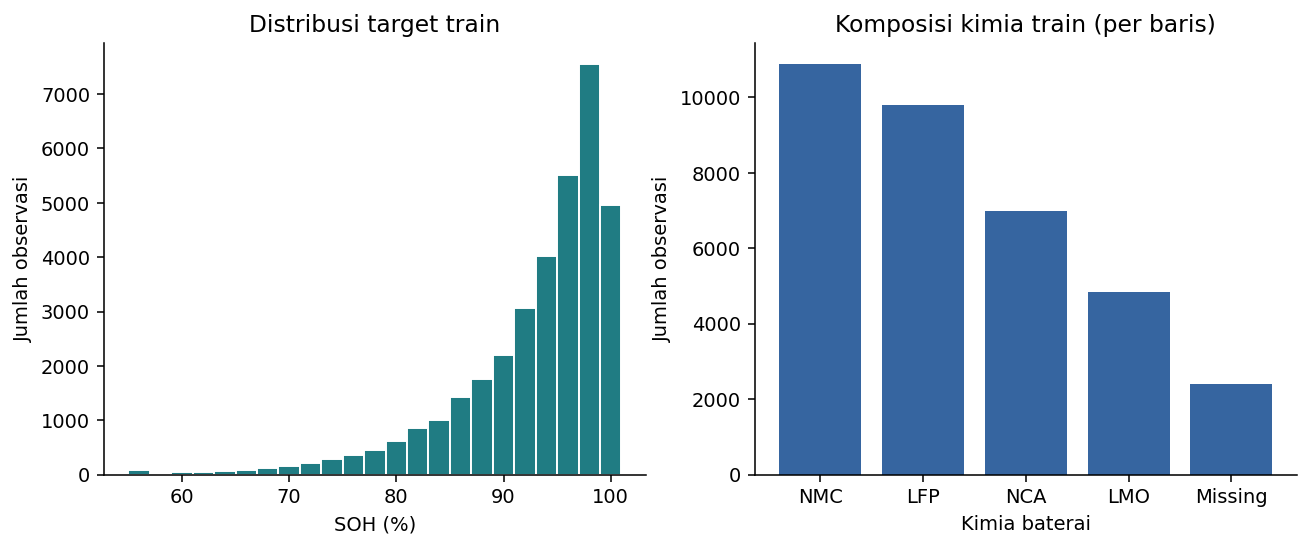

In [9]:
display(audit['bands_train'])
display(audit['statistics_train'].loc[lambda x: x['column'].eq(TARGET)])
display(Image(filename=str(audit['output'] / '02_target_chemistry_train.png'), width=1000))

**Interpretasi:** sebagian besar pengamatan train memiliki SOH tinggi; evaluasi nantinya perlu error per rentang SOH dan jumlah sampelnya. Kimia dihitung per observasi, sehingga baterai dengan banyak pengamatan menyumbang lebih banyak baris. Proporsi data sintetis ini bukan prevalensi kesehatan baterai dunia nyata.

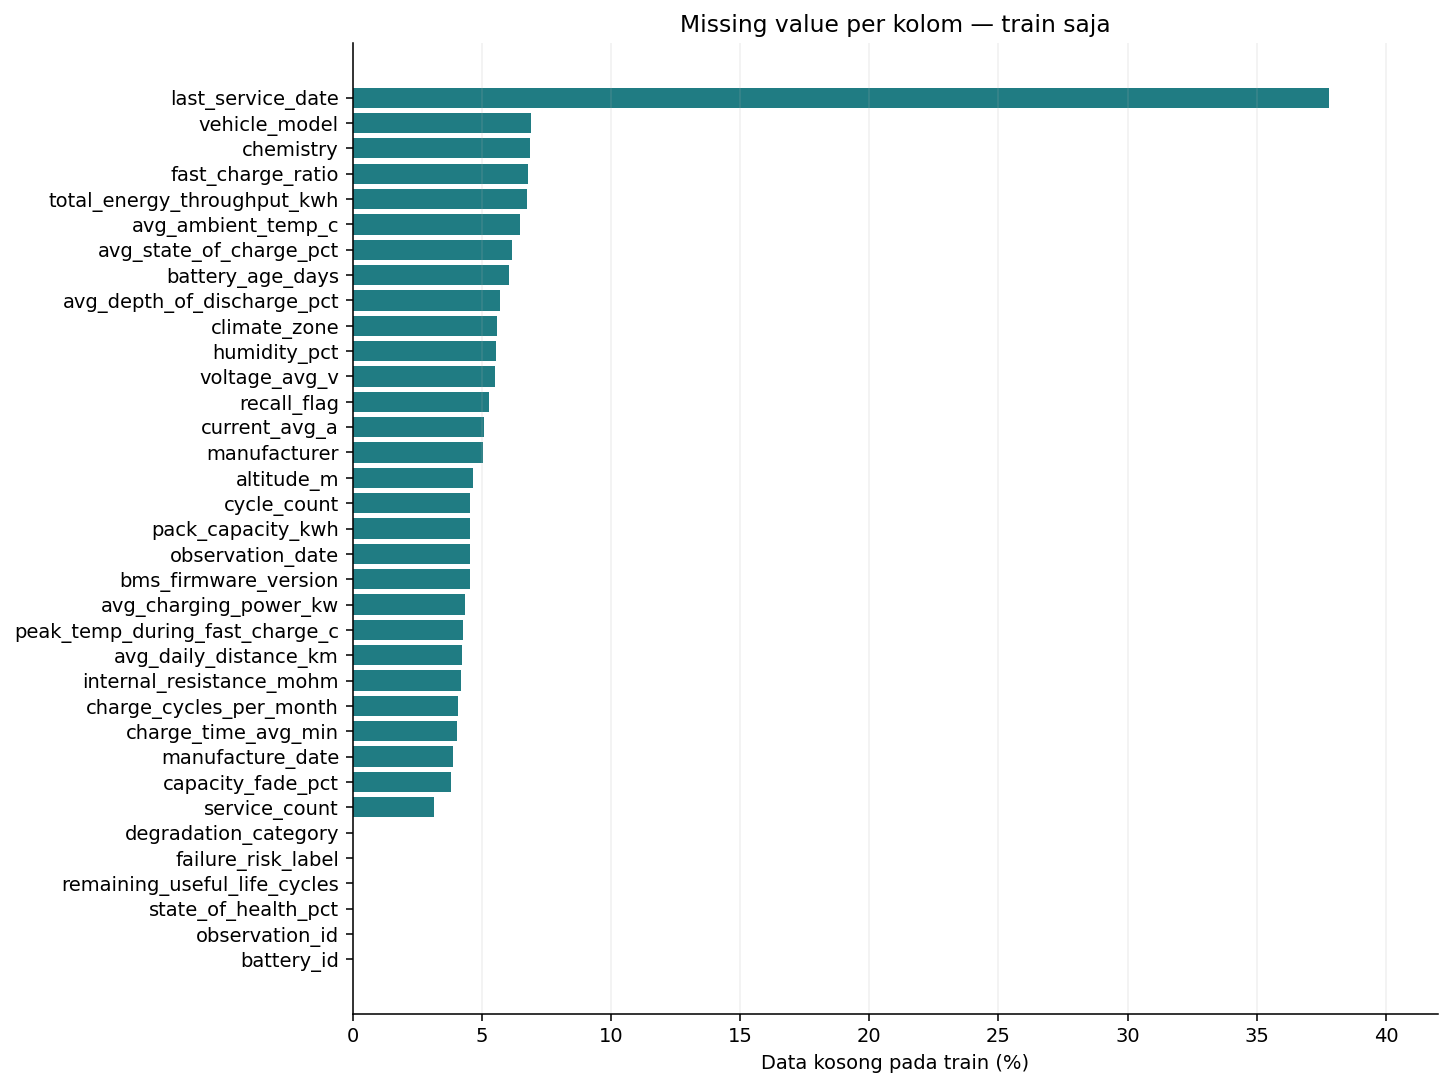

,column,mean,std,min,1%,25%,50%,75%,99%,max
0,pack_capacity_kwh,72.631,14.400,40.100,41.700,62.500,72.500,82.500,99.400,99.900
1,battery_age_days,555.565,476.557,1.000,6.000,167.000,418.000,835.000,1888.870,2184.000
2,cycle_count,572.371,606.371,1.000,4.000,136.000,372.000,800.000,2802.640,5073.000
3,avg_daily_distance_km,50.487,39.826,3.000,4.700,22.500,39.300,66.800,192.657,400.000
4,avg_charging_power_kw,31.975,17.701,1.496,4.200,19.000,28.600,41.800,85.385,147.772
5,fast_charge_ratio,0.293,0.172,0.000,0.000,0.161,0.272,0.405,0.746,0.937
6,avg_depth_of_discharge_pct,64.754,15.820,10.000,26.300,54.100,65.000,75.900,100.000,100.000
7,avg_state_of_charge_pct,67.624,10.127,30.900,43.300,60.800,67.900,74.600,90.300,95.000
8,charge_cycles_per_month,20.307,10.289,2.000,2.000,12.800,19.000,26.600,47.300,57.500
9,total_energy_throughput_kwh,38685.231,42928.649,36.400,292.750,8772.200,24155.300,53217.100,200447.024,402419.900


In [10]:
display(Image(filename=str(audit['output'] / '01_missing_train.png'), width=850))
display(audit['statistics_train'].drop(columns=['count']).round(3))

**Interpretasi:** skala numerik berbeda, misalnya rasio 0–1 dan energi kumulatif dalam kWh. Standardisasi merupakan pilihan awal yang masuk akal untuk optimasi MLP. Parameter scaler/median tetap harus dipelajari dari train pada tahap preprocessing berikutnya, bukan menggunakan tabel global.

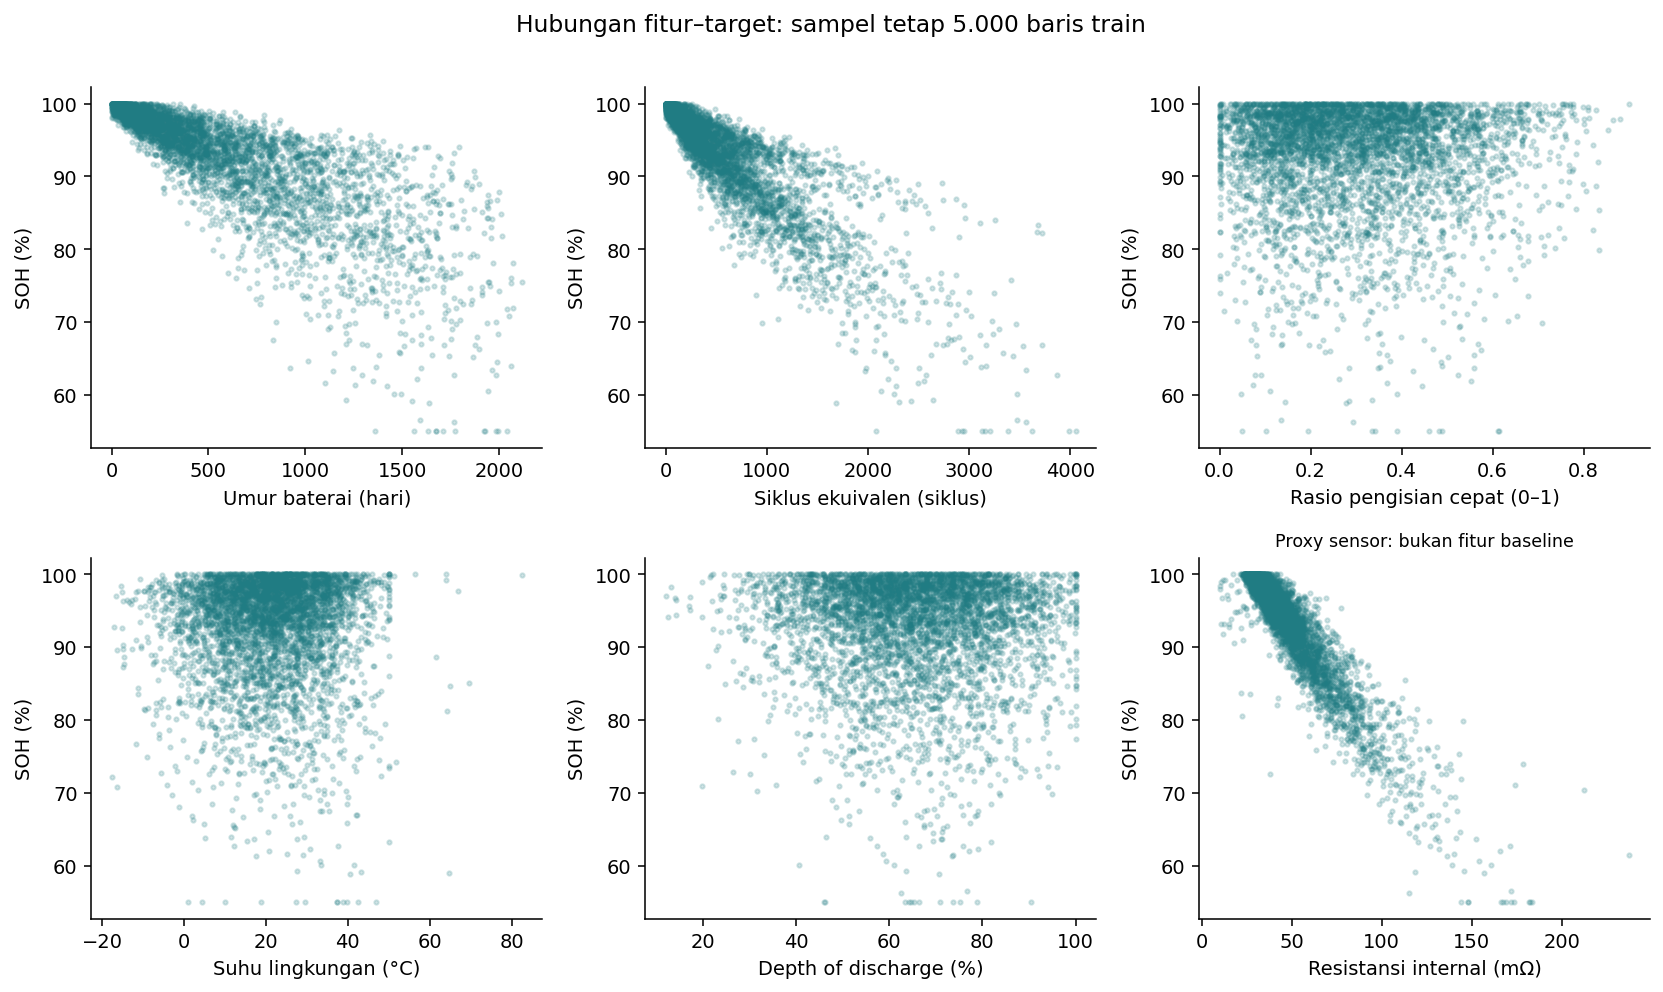

In [11]:
display(Image(filename=str(audit['output'] / '03_relationships_train.png'), width=1100))

**Interpretasi:** hubungan umur/pemakaian dan SOH dapat menjadi alasan menggunakan MLP nonlinear, tetapi grafik tidak membuktikan konfigurasi MLP tertentu akan unggul. Resistance sengaja ditampilkan sebagai diskusi proxy. Plot memakai maksimal 5.000 baris train dengan seed tetap; pasangan missing tidak digambar.

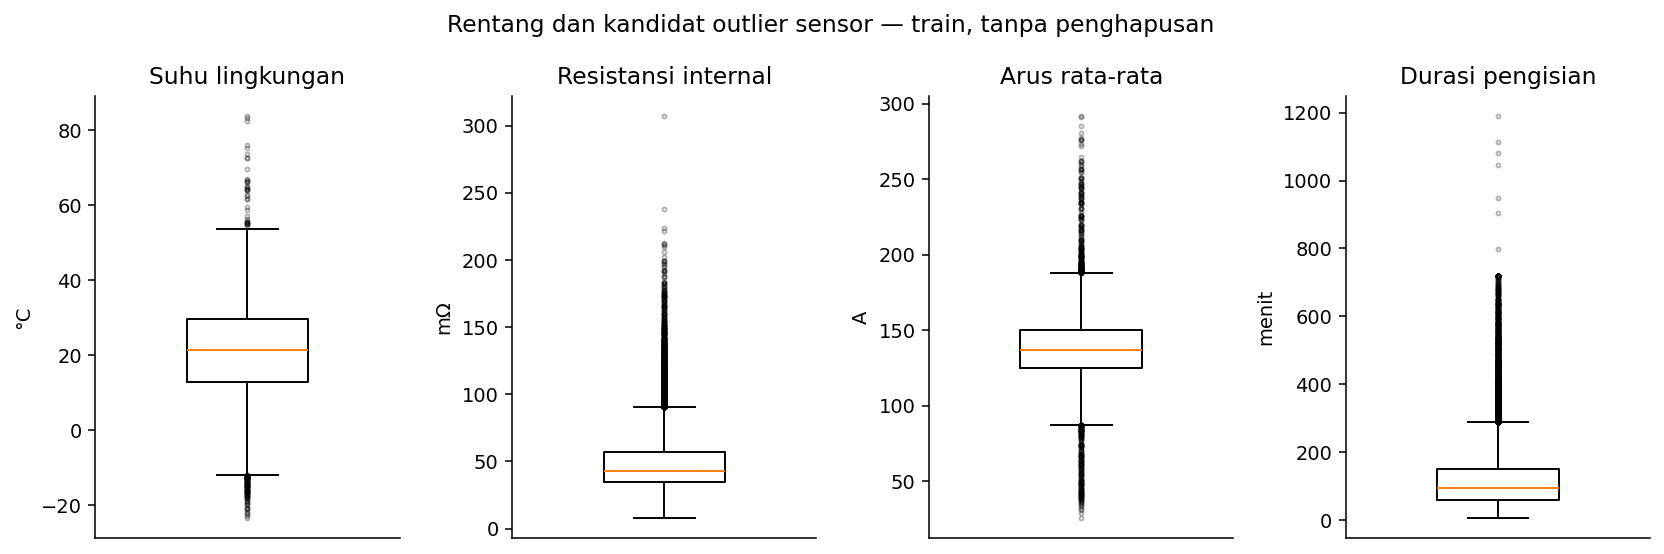

,column,iqr_lower_train,iqr_upper_train,flagged_rows,non_missing_rows,flagged_pct_of_non_missing
19,charge_time_avg_min,-76.300,288.500,2252,33516,6.719
9,total_energy_throughput_kwh,-57895.150,119884.450,1837,32567,5.641
16,internal_resistance_mohm,1.515,90.275,1852,33465,5.534
2,cycle_count,-860.000,1796.000,1684,33337,5.051
15,state_of_health_pct,78.125,110.005,1729,34929,4.950
12,altitude_m,-409.000,911.000,1574,33297,4.727
3,avg_daily_distance_km,-43.950,133.250,1523,33444,4.554
14,service_count,-3.000,5.000,1043,33825,3.084
4,avg_charging_power_kw,-15.200,76.000,787,33416,2.355
18,current_avg_a,87.350,187.750,474,33157,1.430


In [12]:
display(Image(filename=str(audit['output'] / '04_sensor_ranges_train.png'), width=1100))
display(audit['outliers_train'].sort_values('flagged_pct_of_non_missing', ascending=False).round(3))

**Interpretasi:** aturan 1,5×IQR menandai kandidat pemeriksaan, bukan label kesalahan. Tidak ada outlier dihapus atau dipotong pada tahap ini. Sumber menyebut injeksi outlier, tetapi tidak menyediakan mask observasinya. Error domain dan keputusan clipping harus dibahas menggunakan train, bukan ditentukan agar test terlihat bagus.

## 10. Kontrak input baseline

Daftar fitur ini dipilih berdasarkan definisi dan ketersediaan yang diasumsikan pada saat observasi, belum berdasarkan seleksi statistik. Jumlah fitur mentah **berbeda** dari jumlah neuron input setelah one-hot encoding. Recall flag diperlakukan sebagai biner; missing-nya tetap perlu strategi tersendiri.

In [13]:
roles = [('numerik', contract['numeric_features']), ('kategori', contract['categorical_features']), ('biner', contract['binary_features'])]
feature_rows = [{'tipe': kind, 'kolom': c} for kind, columns in roles for c in columns]
display(pd.DataFrame(feature_rows))
assert len(feature_rows) == len(contract['primary_features']) == 21
assert len({row['kolom'] for row in feature_rows}) == 21
assert set(row['kolom'] for row in feature_rows) == set(contract['primary_features'])
print('15 numerik + 5 kategori + 1 biner. Input p ditentukan setelah preprocessing.')

,tipe,kolom
0,numerik,pack_capacity_kwh
1,numerik,battery_age_days
2,numerik,cycle_count
3,numerik,avg_daily_distance_km
4,numerik,avg_charging_power_kw
5,numerik,fast_charge_ratio
6,numerik,avg_depth_of_discharge_pct
7,numerik,avg_state_of_charge_pct
8,numerik,charge_cycles_per_month
9,numerik,total_energy_throughput_kwh


15 numerik + 5 kategori + 1 biner. Input p ditentukan setelah preprocessing.


## 11. Hasil tersimpan dan batas pekerjaan

Hasil yang dapat diperiksa kelompok:
- `results/audit/AUDIT_REPORT.md`: ringkasan keputusan dan temuan.
- `results/audit/schema_audit.csv`: kamus 35 kolom, missing, serta peran fitur.
- `results/audit/quality_summary.json`: pemeriksaan kualitas/temporal.
- `results/audit/numeric_train.csv`, `outlier_flags_train.csv`, `target_bands_train.csv`: statistik train.
- `results/audit/provenance.json`: versi library, hash sumber dan manifest.
- `configs/feature_contract.json`: target dan kebijakan fitur awal.
- `data/splits/battery_split.csv`: pembagian grup yang digunakan bersama.

**Belum selesai pada tahap ini:** EDA lengkap setiap fitur, pipeline preprocessing, pemilihan fitur berbasis eksperimen, training, dan evaluasi test. Notebook ini tidak mengklaim kinerja prediksi atau validitas pada baterai nyata.

In [14]:
expected = [ROOT / 'configs/feature_contract.json', ROOT / 'data/splits/battery_split.csv']
expected += [audit['output'] / name for name in ['AUDIT_REPORT.md', 'schema_audit.csv', 'quality_summary.json', 'provenance.json', 'numeric_train.csv', 'outlier_flags_train.csv', 'target_bands_train.csv']]
assert all(path.is_file() for path in expected)
provenance = json.loads((audit['output'] / 'provenance.json').read_text(encoding='utf-8'))
assert provenance['dataset_sha256'] == contract['dataset_sha256']
print('PASS: artefak audit lengkap dan terikat pada versi dataset yang sama.')
display(pd.Series(provenance['packages'], name='versi').to_frame())

PASS: artefak audit lengkap dan terikat pada versi dataset yang sama.


,versi
numpy,2.2.5
pandas,2.3.2
matplotlib,3.10.6
nbformat,5.10.4
nbclient,0.10.2
ipykernel,6.29.5


## 12. Langkah berikutnya untuk kelompok

1. Tinjau dan sepakati skenario estimasi SOH saat ini pada baterai baru, serta daftar fitur awal.
2. Lanjutkan `01_eda_train.ipynb`: setiap distribusi fitur, kategori langka, korelasi/redundansi, dan alasan pemilihan fitur.
3. Buat `02_preprocessing.ipynb`: imputasi, encoding kategori baru, normalisasi, dan pemeriksaan input, semuanya fit pada train.
4. Hitung jumlah neuron input setelah preprocessing; baru jalankan baseline MLP/backpropagation.
5. Gunakan validation untuk eksperimen. Test tetap dikunci sampai konfigurasi final dipilih.

Lihat `CONTEXT.md` bagian 19–22 untuk penjelasan MLP/backpropagation dan protokol eksperimen.